# 사출 플래그 + 압력 차분 — 틱 AE 피처로 타당한가 (P1, 9/10~10/06)

**넣으려는 피처** (틱마다):
- `Inj_Flag` : 사출 신호가 켜져 있으면 1, 아니면 0 (디지털)
- `dPT1` = PT(t) − PT(t−1), `dPT2` = PT(t) − PT(t−2)
  - `dPT2` 는 생산 AE 에 이미 있는 **`Rolling_PT_Diff_3`** 와 같은 값이다 (`Ana_Preprocess.py`: `pt - pt_history[0]`, 이력 3개).

**증명할 것**
1. 사출 신호가 켜진 틱에서는 압력이 떨어진다.
2. 사출 신호가 꺼진 틱에서는 (다른 이유가 없으면) 떨어지지 않는다.
3. 그래서 플래그가 차분에 대해 정보를 준다 — 어떤 신호(S1~S4)가 가장 그런가, 같은 틱 값을 쓰면 되는가 (지연/유지 필요?).
4. 이 관계가 날마다, 레시피마다 유지되는가 — "지금도" 맞는가.

**데이터**: 9/10~10/06 매일 07:00~23:50, 운전일 20일. **생산 AE 와 같은 태그 8개 + 사출 태그 6개**로 받았다 (`code_ongoing/inj_feat_pull_daily.py`).
틱·샷 정의는 생산 전처리와 같게 맞췄다 (`code_ongoing/inj_feat_lib.py`): 샷 = BuildUp 0→1 또는 Robot_Num 변경, PT 이력은 샷마다 초기화.
"큰 하락" = 차분 ≤ −5 눈금 (사출 없을 때의 흔들림 P99 ≈ 4.5~5.5 눈금).

In [1]:
import sys, os
# 저장소 루트(Log_Extractor.py 가 있는 곳)를 찾아 이동 — 어느 폴더에서 열든, 몇 번을 실행하든 같은 결과
_d = os.path.abspath(os.getcwd())
while not os.path.exists(os.path.join(_d, 'Log_Extractor.py')):
    if os.path.dirname(_d) == _d:
        raise FileNotFoundError('저장소 루트(Log_Extractor.py)를 찾지 못했습니다. 노트북을 KTA_Train 폴더 안에서 열어 주세요.')
    _d = os.path.dirname(_d)
os.chdir(_d)
_code = os.path.join(_d, 'parkkt', 'code_ongoing')
if _code not in sys.path:
    sys.path.insert(0, _code)
from inj_feat_viz import *
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40)
T = load_all()          # 데이터 갱신 후에는 load_all(force=True)
print(f'BuildUp 틱 {len(T):,}개, 운전일 {T.day.nunique()}일, 샷 {T.shot.nunique():,}개')

BuildUp 틱 893,883개, 운전일 20일, 샷 58,012개


## 0. 먼저: 사출 태그를 추가해도 틱이 그대로인가

DB 는 값이 바뀐 태그만 기록하므로, **사출 태그를 같이 받으면 "사출 태그만 바뀐 스캔"이 새 행으로 끼어든다.** 그 행은 생산 AE 에는 없는 틱이고, PT 가 안 바뀌었으니 차분이 항상 0 이다 — 하필 사출 신호가 바뀌는 순간에만 생겨서 사출 시점 차분을 0 으로 희석시킨다.
- 10/06 09:00~10:00 실측: 생산 8태그 6,598행 / +사출 6태그 6,632행 (+34). "생산 태그가 직전과 전부 같고 사출 태그만 바뀐 행"을 지우면 **6,598행, 타임스탬프까지 생산과 정확히 일치** (`code_ongoing/inj_feat_tick_check.py`).
- 아래 분석은 전부 이 제거를 거친 "생산과 같은 틱" 위에서 했다.

> **실서비스 적용 시 같은 처리가 필요하다**: 실시간 전처리에 사출 태그를 추가하면, 사출 태그만 바뀐 틱은 건너뛰거나(차분·Tick_Index 갱신 안 함) 플래그 값만 갱신해야 학습 때와 틱이 같아진다.

In [2]:
rm = pd.Series(T.attrs['removed']); print(f'하루 평균 제거된 행: {rm.mean():.0f}  (하루 행수 대비 약 0.6%)')
print('S4(S2 ∧ FOAMING) 와 S2 가 같은 값인 틱 비율:', (T.S4 == T.S2).mean())

하루 평균 제거된 행: 644  (하루 행수 대비 약 0.6%)
S4(S2 ∧ FOAMING) 와 S2 가 같은 값인 틱 비율: 1.0


S4 는 S2 와 **모든 틱에서 같다** (S2 가 항상 FOAMING 안에서만 켜지므로). 이후 S4 는 S2 와 같은 후보로 보고 따로 그리지 않는다.

## 1. 신호가 켜지는 순간 압력은 어떻게 움직이나

각 신호가 0→1 로 켜지는 틱을 0 으로 맞추고, 앞뒤 틱의 `dPT1` 을 평균냈다 (Tick_Index ≥ 3, 같은 샷 안). 실선 = 연휴 전, 파선 = 연휴 후. 맨 아래 = 그 틱에 신호가 아직 켜져 있는 비율.

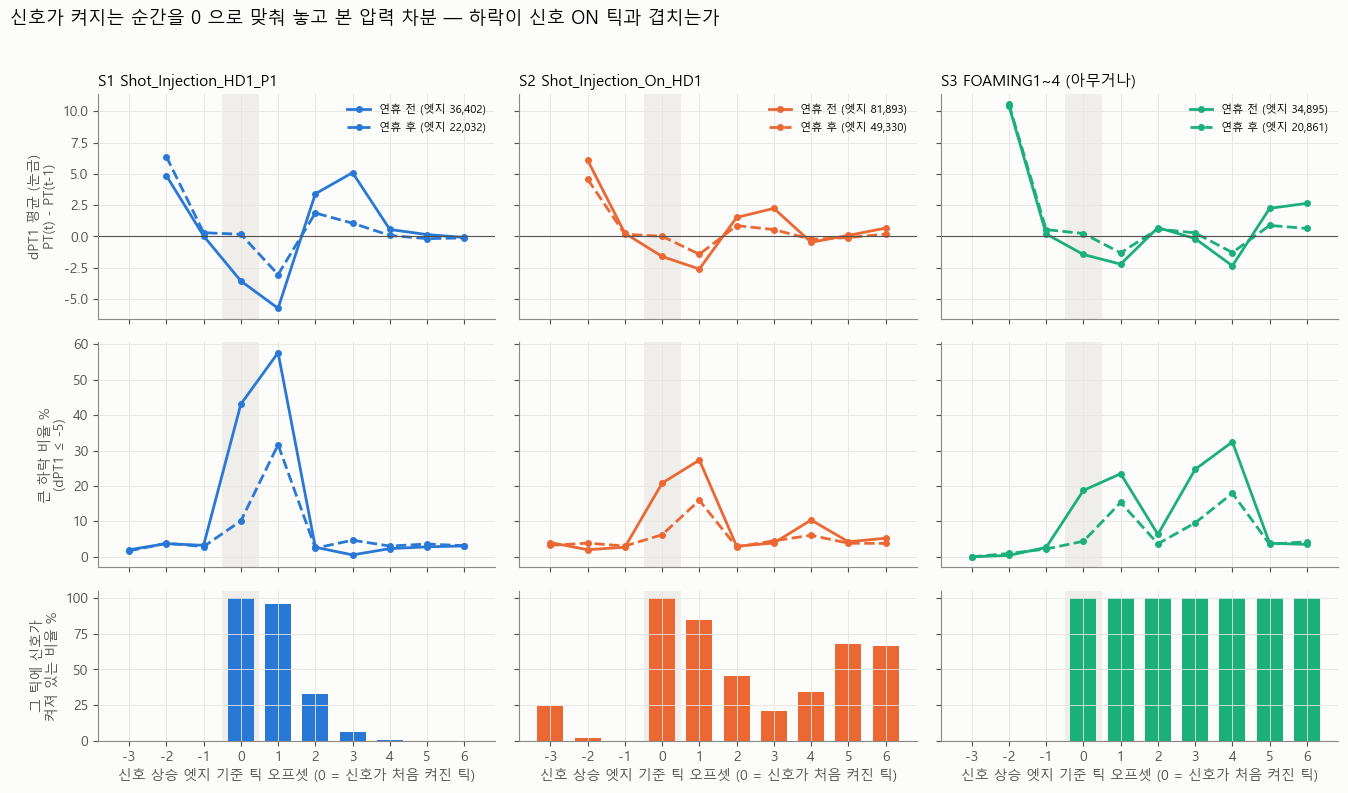

In [3]:
fig_profile(T); plt.show()

**S1** — 켜지는 틱(0)과 그다음 틱(+1)에서 압력이 떨어지고(연휴 전 평균 −4, −6 눈금, 큰 하락 50~60%), S1 이 꺼지는 +2~+3 에서 회복(+)한다. S1 은 대부분 2틱이라 **"S1 이 켜져 있는 틱 = 압력이 떨어지는 틱"이 거의 정확히 겹친다.** → 같은 틱의 S1 값을 그대로 쓰면 되고, 지연(lag)이나 유지(hold)가 필요 없다.
- 연휴 후(파선)에는 하락이 첫 틱(0)보다 **둘째 틱(+1)에** 몰린다 (큰 하락 10% → 31%). 하락이 약 1틱(0.5초) 늦게 오는 셈인데, S1 이 +1 에서도 96% 켜져 있어 여전히 "S1 ON 틱 안"이다. (늦어진 것 자체는 연휴 전후 설비 변화의 또 다른 단서.)

**S2** — 같은 모양이지만 약하다. S2 의 상승 엣지 절반 이상은 P1 사출이 아닌 때(같은 헤드 짝펌프 사출, FOAMING 3 단계)라서 압력이 안 떨어지는 엣지가 섞인다.

**S3 (FOAMING)** — 켜진 뒤 7틱 내내 ON 인데 하락은 +3~+4 에서 난다 (그때 S1 이 켜지므로). 거의 항상 켜져 있어서 ON/OFF 가 하락 시점을 구분하지 못한다.

## 2. ON 틱 vs OFF 틱 — 분포 비교

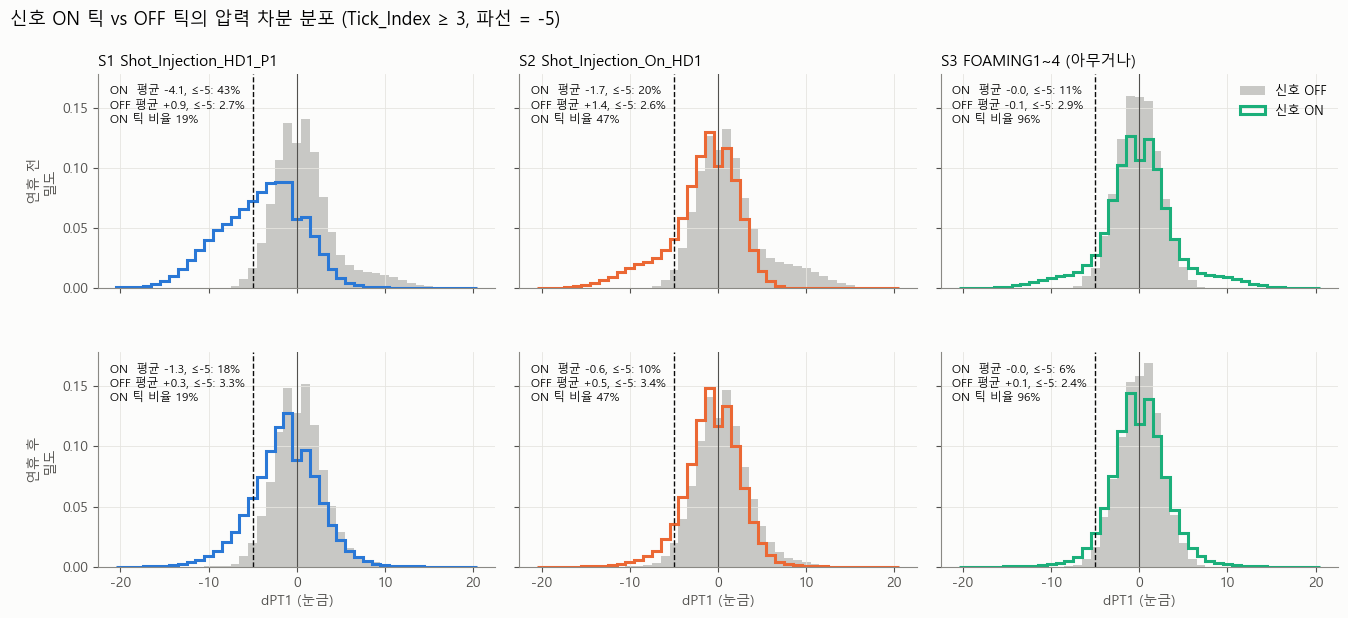

In [4]:
fig_onoff_hist(T, col='dPT1'); plt.show()

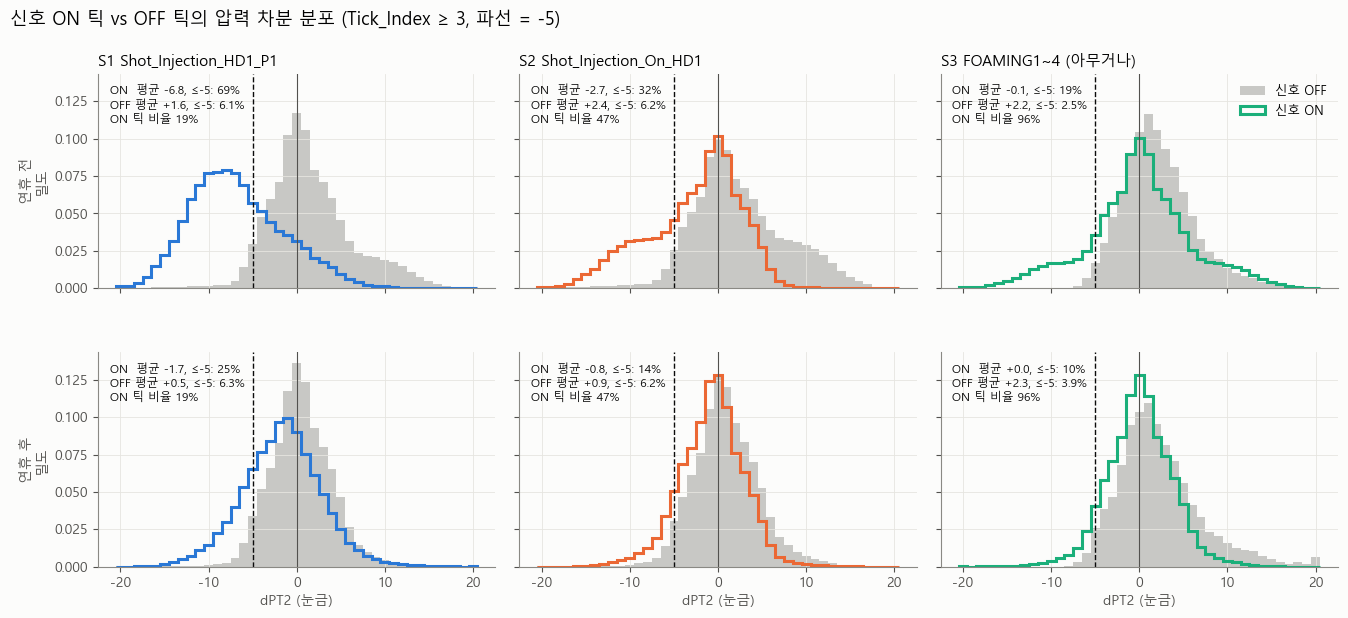

In [5]:
fig_onoff_hist(T, col='dPT2'); plt.show()

- **S1 ON** 틱의 분포는 왼쪽(하락)으로 길게 늘어지고, **OFF** 틱은 0 근처에 모여 있다. OFF 평균이 약간 + 인 건 S1 이 꺼진 직후의 회복 틱이 OFF 에 들어가기 때문이다 ("꺼지면 떨어지지 않는다"와 모순되지 않음).
- `dPT2` 는 하락이 2틱에 걸쳐 쌓인 걸 한 번에 보므로 ON/OFF 차이가 더 크다 (연휴 전 ON 큰 하락 69%).

## 3. 후보 전체 비교 — 어떤 신호, 어떤 정렬인가

- `_lag1` = 한 틱 전 신호, `_hold1/2` = 최근 1/2틱 안에 신호가 있었음 (신호를 뒤로 늘림).
- **배율** = ON 틱의 큰 하락 비율 ÷ OFF 틱의 큰 하락 비율 — "켜졌을 때 떨어지고, 꺼졌을 때 안 떨어진다"의 세기.
- **MI(bits)** = 플래그와 차분(구간화) 사이 상호정보량 — 플래그가 차분에 대해 알려주는 정보량. 0 이면 무관.

In [6]:
cands = ['S1', 'S1_lag1', 'S1_hold1', 'S1_hold2', 'S2', 'S2_lag1', 'S2_hold1', 'S3', 'S4']
for col in ['dPT1', 'dPT2']:
    for er in ['연휴 전', '연휴 후']:
        print(f'==== {col} · {er}')
        display(pd.DataFrame({c: flag_metrics(T[T.era == er], c, col) for c in cands}).T.round(3))

==== dPT1 · 연휴 전


,플래그 ON 비율%,ON 평균,OFF 평균,ON P10,OFF P10,ON 큰하락%(≤-5),OFF 큰하락%,배율(ON/OFF),큰하락 중 ON 비율%,MI(bits)
S1,19.212,-4.078,0.917,-10.0,-3.0,43.398,2.749,15.784,78.964,0.192
S1_lag1,19.296,0.232,-0.108,-9.0,-4.0,25.554,6.974,3.664,46.698,0.137
S1_hold1,27.341,-0.883,0.274,-9.0,-3.0,30.716,2.974,10.327,79.533,0.204
S1_hold2,35.435,-0.026,-0.051,-8.0,-3.0,23.906,3.234,7.393,80.228,0.213
S2,46.621,-1.701,1.406,-7.0,-3.0,19.622,2.643,7.423,86.636,0.121
S2_lag1,46.609,0.063,-0.135,-5.0,-4.0,12.492,8.872,1.408,55.141,0.022
S2_hold1,64.707,-0.403,0.618,-6.0,-3.0,14.815,2.756,5.374,90.787,0.045
S3,96.163,-0.041,-0.079,-5.0,-3.0,10.865,2.880,3.773,98.954,0.008
S4,46.621,-1.701,1.406,-7.0,-3.0,19.622,2.643,7.423,86.636,0.121


==== dPT1 · 연휴 후


,플래그 ON 비율%,ON 평균,OFF 평균,ON P10,OFF P10,ON 큰하락%(≤-5),OFF 큰하락%,배율(ON/OFF),큰하락 중 ON 비율%,MI(bits)
S1,19.454,-1.340,0.318,-6.0,-3.0,18.454,3.285,5.617,57.568,0.048
S1_lag1,19.552,0.005,-0.007,-6.0,-3.0,14.462,4.237,3.413,45.341,0.049
S1_hold1,27.743,0.055,-0.027,-5.0,-3.0,13.184,3.569,3.695,58.653,0.063
S1_hold2,36.026,0.025,-0.021,-5.0,-3.0,11.565,3.236,3.574,66.808,0.062
S2,46.520,-0.607,0.520,-4.0,-3.0,9.506,3.392,2.802,70.909,0.026
S2_lag1,46.531,-0.008,-0.001,-4.0,-3.0,7.973,4.725,1.687,59.487,0.009
S2_hold1,64.870,-0.002,-0.009,-4.0,-3.0,7.480,3.939,1.899,77.812,0.011
S3,96.077,-0.008,0.089,-4.0,-3.0,6.392,2.426,2.635,98.474,0.003
S4,46.520,-0.607,0.520,-4.0,-3.0,9.506,3.392,2.802,70.909,0.026


==== dPT2 · 연휴 전


,플래그 ON 비율%,ON 평균,OFF 평균,ON P10,OFF P10,ON 큰하락%(≤-5),OFF 큰하락%,배율(ON/OFF),큰하락 중 ON 비율%,MI(bits)
S1,19.212,-6.767,1.627,-13.0,-4.0,69.312,6.062,11.434,73.112,0.298
S1_lag1,19.296,-3.841,0.936,-13.0,-4.0,56.737,9.003,6.302,60.108,0.202
S1_hold1,27.341,-3.745,1.429,-12.0,-4.0,52.959,5.139,10.305,79.498,0.259
S1_hold2,35.435,-0.712,0.413,-12.0,-4.0,40.864,5.783,7.067,79.502,0.338
S2,46.621,-2.731,2.412,-11.0,-4.0,31.948,6.218,5.138,81.777,0.171
S2_lag1,46.609,-1.644,1.462,-10.0,-5.0,27.314,10.269,2.660,69.899,0.057
S2_hold1,64.707,-1.560,2.901,-10.0,-3.0,25.886,4.146,6.244,91.966,0.114
S3,96.163,-0.072,2.178,-8.0,-3.0,18.840,2.523,7.467,99.469,0.010
S4,46.621,-2.731,2.412,-11.0,-4.0,31.948,6.218,5.138,81.777,0.171


==== dPT2 · 연휴 후


,플래그 ON 비율%,ON 평균,OFF 평균,ON P10,OFF P10,ON 큰하락%(≤-5),OFF 큰하락%,배율(ON/OFF),큰하락 중 ON 비율%,MI(bits)
S1,19.454,-1.688,0.545,-7.0,-4.0,25.371,6.289,4.034,49.353,0.054
S1_lag1,19.552,-1.324,0.459,-7.0,-4.0,24.149,6.562,3.680,47.212,0.046
S1_hold1,27.743,-0.793,0.457,-7.0,-4.0,20.662,5.908,3.497,57.315,0.049
S1_hold2,36.026,0.138,0.095,-6.0,-4.0,16.031,6.605,2.427,57.747,0.054
S2,46.520,-0.776,0.882,-5.0,-4.0,14.395,6.179,2.330,66.958,0.036
S2_lag1,46.531,-0.613,0.740,-5.0,-4.0,13.815,6.682,2.068,64.278,0.024
S2_hold1,64.870,-0.386,1.027,-5.0,-4.0,12.480,5.423,2.301,80.949,0.024
S3,96.077,0.022,2.273,-5.0,-3.0,10.250,3.895,2.632,98.472,0.008
S4,46.520,-0.776,0.882,-5.0,-4.0,14.395,6.179,2.330,66.958,0.036


**결론: S1 (`Shot_Injection_HD1_P1`), 같은 틱 값 그대로.**
- 배율이 모든 경우에 가장 높다 (dPT1 연휴 전 15.8배 / 연휴 후 5.6배; S2 는 7.4 / 2.8, S3 는 3.8 / 2.6).
- ON 평균이 뚜렷이 음수이고 OFF 평균은 0 근처 — "ON = 하락, OFF = 하락 없음" 의미가 그대로 살아 있는 건 S1 뿐.
- `lag1` 은 확실히 나빠진다 (배율 15.8 → 3.7) → 하락은 신호와 **같은 틱**에 난다.
- `hold2` 는 MI 가 비슷하거나 약간 높지만 ON 평균이 0 이 된다 — 하락과 회복이 같이 ON 에 들어가 상쇄되기 때문. 정보량은 비슷해도 "켜지면 떨어진다"는 의미가 흐려지므로 raw S1 을 권장.
- S3 는 틱의 96% 가 ON 이라 플래그로서 정보가 거의 없다 (MI 0.003~0.01). S4 = S2.

## 4. 신호가 꺼져 있는데 큰 하락이 난 틱은 무엇이었나

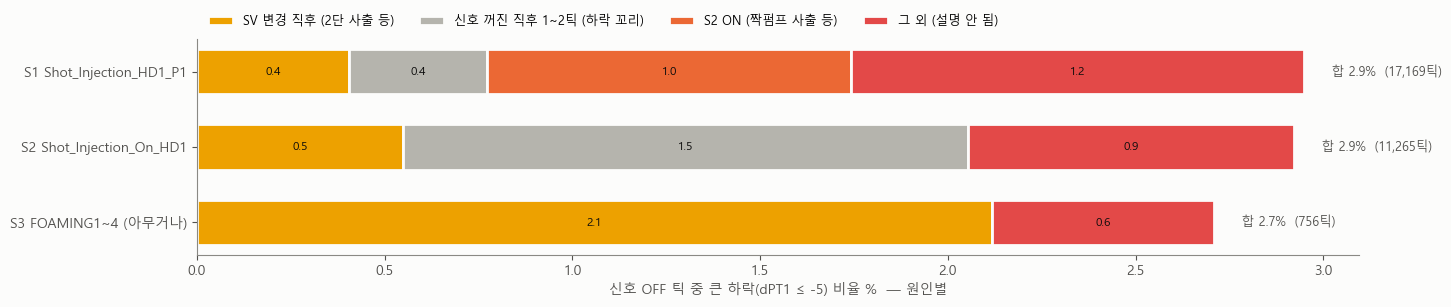

S1 {'그 외 (설명 안 됨)': 1.21, 'S2 ON (짝펌프 사출 등)': 0.97, 'SV 변경 직후 (2단 사출 등)': 0.4, '신호 꺼진 직후 1~2틱 (하락 꼬리)': 0.37}
S2 {'신호 꺼진 직후 1~2틱 (하락 꼬리)': 1.51, '그 외 (설명 안 됨)': 0.87, 'SV 변경 직후 (2단 사출 등)': 0.55}


S3 {'SV 변경 직후 (2단 사출 등)': 2.12, '그 외 (설명 안 됨)': 0.59}


In [7]:
fig_off_breakdown(T); plt.show()
for s in ['S1', 'S2', 'S3']:
    vc, n, n_off = off_drop_breakdown(T, s); print(s, (vc / n_off * 100).round(2).to_dict())

S1 OFF 틱 중 큰 하락은 2.9% 이고, 그중
- 0.97%p 는 **S2 가 켜진 틱** (S1 은 꺼졌지만 헤드 사출 중 — 짝펌프 사출의 영향),
- 0.40%p 는 **SV 변경 직후** (2단 사출 레시피의 SV 하향 → 생산 AE 의 `Phase_Transition` 이 같은 틱/직전에 1 로 알려준다),
- 0.37%p 는 **S1 이 꺼진 직후 1~2틱** (하락 꼬리),
- **설명 안 되는 것은 1.2%** — 사출 없을 때의 자연 흔들림 상위 1% 수준과 같다.

→ "사출 신호가 없으면 떨어지지 않는다"가 성립한다. 남는 1.2% 가 AE 입장에서 "평소 노이즈"이고, 이보다 자주/크게 떨어지면 재구성 오차로 드러난다.

## 5. 날마다, 레시피마다 유지되나 ("지금도" 맞나)

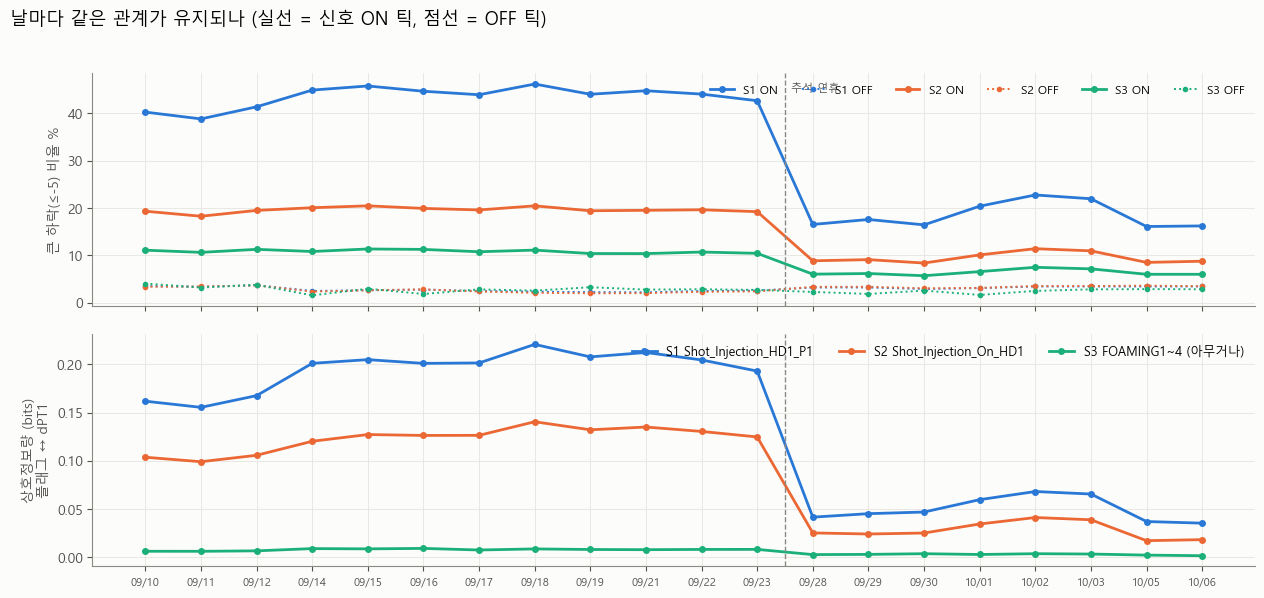

In [8]:
fig_daily(T); plt.show()

In [9]:
display(daily_metrics(T, 'S1')[['ON 평균', 'OFF 평균', f'ON 큰하락%(≤-{BIG})', 'OFF 큰하락%', '배율(ON/OFF)', 'MI(bits)']].round(2))

,ON 평균,OFF 평균,ON 큰하락%(≤-5),OFF 큰하락%,배율(ON/OFF),MI(bits)
day,,,,,,
2026-09-10,-3.60,0.85,40.26,3.52,11.43,0.16
2026-09-11,-3.45,0.77,38.82,3.37,11.52,0.16
2026-09-12,-3.73,0.84,41.38,3.71,11.16,0.17
2026-09-14,-4.14,0.90,44.90,2.50,17.94,0.20
2026-09-15,-4.36,0.96,45.77,2.64,17.31,0.20
2026-09-16,-4.27,0.94,44.66,2.79,15.98,0.20
2026-09-17,-4.31,0.96,43.92,2.48,17.70,0.20
2026-09-18,-4.46,1.02,46.18,2.35,19.65,0.22
2026-09-19,-4.19,0.94,44.03,2.26,19.51,0.21


In [10]:
sv_table(T, 'S1')

평균       ≤-5 %              n            배율
S1               OFF    ON   OFF     ON     OFF     ON ON/OFF
era  svb                                                     
연휴 전 SV ≤2100   1.14 -5.22  2.53  51.70   70868  15815  20.42
     2101~2200  1.12 -4.94  2.47  50.34   78446  18122  20.35
     2201~2400  0.91 -3.39  2.57  36.88   70977  20022  14.34
     2401~2600  0.48 -3.46  5.90  39.19   22965   6482   6.65
     >2600      0.74 -3.48  2.56  39.65  122307  26494  15.46
연휴 후 SV ≤2100   0.68 -3.17  2.73  35.78   43511   9607  13.09
     2101~2200  0.41 -1.79  2.95  20.68   44206  10105   7.01
     2201~2400  0.27 -0.73  2.97  10.63   22384   8384   3.58
     2401~2600  0.07 -0.69  3.88  13.14   34101   7175   3.39
     >2600      0.18 -0.62  3.64  13.46   72459  17060   3.70

- **방향은 20일 모두, 모든 레시피에서 같다**: S1 ON 틱의 하락 비율이 OFF 보다 항상 높고, ON 평균은 항상 음수.
- **세기는 추석 연휴를 기점으로 크게 줄었다**: 연휴 전 배율 14~20 → 연휴 후 SV ≤2100 은 13, 그 이상은 3.4~7. 고유량 레시피(SV >2200)의 연휴 후 ON 평균은 −0.6~−0.7 눈금으로 약하다 (이전 노트북 `사출했는데_압력안떨어짐_분석.ipynb` 와 같은 현상).
- 로깅·틱 정의는 기간 내내 같으므로 이건 설비 거동 변화다. 원인 확인 필요 (연휴 중 HD1/P1 작업 여부).

## 6. 정리 — AE 피처 제안

| 피처 | 정의 | 근거 |
|---|---|---|
| `Inj_Flag` | **`Shot_Injection_HD1_P1` 의 같은 틱 값 (0/1)** | 배율·의미 모두 최선, 지연/유지 불필요 (1·3절) |
| `dPT1` | PT(t) − PT(t−1), 샷 안에서 | 하락 시점이 신호와 정확히 겹침 |
| `dPT2` | PT(t) − PT(t−2) = 기존 `Rolling_PT_Diff_3` | 이미 있음. ON/OFF 차이가 가장 큼 |

**주의할 점**
1. **틱 정의**: 사출 태그 추가로 생기는 "사출 태그만 바뀐 틱"은 학습·실시간 모두 제거해야 한다 (0절). 안 하면 사출 순간 차분이 0 으로 희석된다.
2. **SV 변경**: 플래그 없이 떨어지는 경우 중 SV 하향이 있다 — 기존 `Phase_Transition` 이 같이 들어가 있어야 AE 가 이걸 정상으로 배운다. 단 `Phase_Transition` 은 SV 가 바뀐 그 틱만 1 이고 압력은 1~2틱 뒤에 따라 내려가므로, 필요하면 "최근 3틱 안 SV 변경" 으로 넓히는 걸 검토.
3. **레시피 의존**: 하락 크기가 SV 에 따라 다르다 (ON 평균 −0.6 ~ −5 눈금). `g_s_SV`, `Scale_Out___PT` 가 이미 입력에 있어 AE 가 조건부로 배울 수 있다.
4. **학습 구간**: 연휴 전후로 관계의 세기가 달라졌다. 연휴 전 데이터로 학습하면 연휴 후 전체가 "사출했는데 덜 떨어짐"으로 재구성 오차가 커질 것이다 — 그게 원하는 탐지인지(설비 변화), 새 정상인지(정비 결과) 정한 뒤 학습 구간을 고를 것.
5. 이건 **피처의 타당성**(신호↔차분 관계가 실재하고 일관됨)을 보인 것이고, AE 에 넣었을 때 이상 탐지 성능이 좋아지는지는 별도로 재학습해서 확인해야 한다.